# FitLoop - Growth model

Monthly model: spend → signups → activation → trial → paid → churn → revenue.
Used to test the CEO's plan (double the budget) against other options.

## 1. Data
Cleaned files from `cleaning.ipynb`, loaded the same way as in `analysis.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

EXTRACTION = pd.Timestamp("2026-06-30")
PRODUCT_CHANGE = pd.Timestamp("2025-10-01")
CHANNELS = ["Google Ads", "Influencers", "Meta Ads", "Organic", "Referral", "TikTok Ads"]
PAID_CHANNELS = ["Google Ads", "Influencers", "Meta Ads", "TikTok Ads"]

user = pd.read_csv("../data/users_cleaned.csv").drop(columns=["Unnamed: 0"], errors="ignore")
mark = pd.read_csv("../data/marketing_spend_cleaned.csv").drop(columns=["Unnamed: 0"], errors="ignore")
for c in ["signup_date", "trial_start_date", "subscription_start_date", "subscription_end_date"]:
    user[c] = pd.to_datetime(user[c])
mark["month"] = pd.to_datetime(mark["month"])

assert len(user) == 70_237 and len(mark) == 72, "re-run cleaning.ipynb"


Helper columns. `mature` = signed up at least 14 days before extraction (enough time to pay); conversion rates use mature users only.

In [2]:
user["cohort"] = user["signup_date"].dt.to_period("M")
user["trial"] = user["trial_start_date"].notna()
user["paid"] = user["subscription_start_date"].notna()
user["churned"] = user["subscription_end_date"].notna()
user["period"] = np.where(user["signup_date"] >= PRODUCT_CHANGE, "post", "pre")
user["mature"] = user["signup_date"] <= pd.Timestamp("2026-06-16")
user["paid_days"] = (user["subscription_end_date"].fillna(EXTRACTION) - user["subscription_start_date"]).dt.days

mature = user[user["mature"]]

MONTHS = pd.period_range("2025-01", "2026-06", freq="M")
spend = (mark.assign(month=mark["month"].dt.to_period("M"))
             .pivot(index="month", columns="channel", values="spend_eur").reindex(MONTHS)[PAID_CHANNELS])
signups = (user.pivot_table(index="cohort", columns="channel", values="user_id", aggfunc="count")
               .reindex(MONTHS).fillna(0)[CHANNELS])

## 2. Parameters
All model rates in one dict, computed from the data. Scenarios only change `PARAMS`.

- Activation is split pre/post 1 Oct 2025 (the product change raised it).
- Trial and trial → paid are split by activated / not activated. Trial → paid did not change after 1 Oct, so both periods are pooled.
- Annual renewal is one value for all channels (only 298 renewals observed).
- Revenue: monthly plan €9.99 each month; annual plan €59.99 at start and at each renewal.

In [3]:
t = mature[mature["trial"]]
print("trial -> paid by period:")
print(t.pivot_table(index="period", columns="activated_d7", values="paid", aggfunc="mean").round(3))

payers = user[user["paid"]]
monthly_subs = payers[payers["plan"] == "monthly"]
annual = payers[payers["plan"] == "annual"]
renewal_due = annual[annual["subscription_start_date"] <= pd.Timestamp("2025-06-30")]

def churn_rate(d):  # cancellations per subscriber-month observed (same as analysis.ipynb)
    return d["churned"].sum() / (d["paid_days"].sum() / 30.44)

rates = pd.DataFrame({
    "act_pre":        mature[mature["period"] == "pre"].groupby("channel")["activated_d7"].mean(),
    "act_post":       mature[mature["period"] == "post"].groupby("channel")["activated_d7"].mean(),
    "trial_act":      mature[mature["activated_d7"] == 1].groupby("channel")["trial"].mean(),
    "trial_noact":    mature[mature["activated_d7"] == 0].groupby("channel")["trial"].mean(),
    "paid_act":       t[t["activated_d7"] == 1].groupby("channel")["paid"].mean(),
    "paid_noact":     t[t["activated_d7"] == 0].groupby("channel")["paid"].mean(),
    "annual_share":   payers.groupby("channel")["plan"].apply(lambda s: (s == "annual").mean()),
    "monthly_churn":  monthly_subs.groupby("channel")[["churned", "paid_days"]].apply(churn_rate),
}).loc[CHANNELS]

PARAMS = {
    "rates": rates,
    "annual_renewal": 1 - renewal_due["churned"].mean(),
    "price_monthly": 9.99,
    "price_annual": 59.99,
}
print(f"annual renewal: {PARAMS['annual_renewal']:.1%}")
rates.round(3)

trial -> paid by period:
activated_d7      0      1
period                    
post          0.156  0.437
pre           0.163  0.442
annual renewal: 54.4%


,act_pre,act_post,trial_act,trial_noact,paid_act,paid_noact,annual_share,monthly_churn
channel,,,,,,,,
Google Ads,0.348,0.516,0.577,0.108,0.506,0.187,0.255,0.088
Influencers,0.243,0.331,0.604,0.094,0.366,0.150,0.229,0.128
Meta Ads,0.300,0.431,0.599,0.099,0.447,0.182,0.250,0.109
Organic,0.382,0.583,0.602,0.104,0.487,0.190,0.249,0.087
Referral,0.478,0.671,0.605,0.096,0.572,0.222,0.235,0.070
TikTok Ads,0.161,0.235,0.598,0.098,0.284,0.119,0.237,0.175


Check: the funnel rates should give back the observed signup → paid rate per channel (post-Oct users).

In [4]:
r = rates
implied = r["act_post"] * r["trial_act"] * r["paid_act"] + (1 - r["act_post"]) * r["trial_noact"] * r["paid_noact"]
observed = mature[mature["period"] == "post"].groupby("channel")["paid"].mean()
pd.DataFrame({"implied": implied, "observed": observed}).round(3)

,implied,observed
channel,,
Google Ads,0.161,0.158
Influencers,0.083,0.086
Meta Ads,0.126,0.129
Organic,0.179,0.175
Referral,0.239,0.248
TikTok Ads,0.049,0.049


## 3. Spend → signups
For Google, Meta and TikTok we fit `signups = a · spend^b` on monthly data (log-log regression).
`b < 1` means diminishing returns: doubling spend gives less than double the signups.
Months with no spend (TikTok before Jun 2025) and Meta Aug 2025 (spend unknown) are left out.

In [5]:
import statsmodels.api as sm

curves = {}
for ch in ["Google Ads", "Meta Ads", "TikTok Ads"]:
    d = pd.DataFrame({"spend": spend[ch], "signups": signups[ch]}).dropna()
    d = d[d["spend"] > 0]
    fit = sm.OLS(np.log(d["signups"]), sm.add_constant(np.log(d["spend"]))).fit()
    lo, hi = fit.conf_int().loc["spend"]
    curves[ch] = {"a": np.exp(fit.params["const"]), "b": fit.params["spend"],
                  "b_low": lo, "b_high": hi, "r2": fit.rsquared, "n": len(d),
                  "spend_min": d["spend"].min(), "spend_max": d["spend"].max()}

curves_tbl = pd.DataFrame(curves).T
curves_tbl["signups_if_spend_x2"] = 2 ** curves_tbl["b"]
curves_tbl.round(2)

,a,b,b_low,b_high,r2,n,spend_min,spend_max,signups_if_spend_x2
Google Ads,0.31,0.94,0.79,1.09,0.92,18.0,1910.0,4280.0,1.92
Meta Ads,3.90,0.65,0.59,0.70,0.98,17.0,2970.0,10820.0,1.57
TikTok Ads,1.42,0.85,0.68,1.03,0.91,13.0,2800.0,5250.0,1.81


Influencers: only three campaigns, all €9,000, so a curve cannot be fitted. We use the average signups per euro of those campaigns (linear, `b = 1`). This is optimistic for bigger campaigns.

In [6]:
bursts = pd.DataFrame({"spend": spend["Influencers"], "signups": signups["Influencers"]})
bursts = bursts[bursts["spend"] > 0]
display(bursts)
curves["Influencers"] = {"a": bursts["signups"].sum() / bursts["spend"].sum(), "b": 1.0}

PARAMS["curves"] = {ch: {"a": c["a"], "b": c["b"]} for ch, c in curves.items()}
PARAMS["curves"]

,spend,signups
2025-03,9000.0,2527.0
2025-09,9000.0,2534.0
2026-02,9000.0,2644.0


{'Google Ads': {'a': np.float64(0.3130298670979532),
  'b': np.float64(0.9401053740825258)},
 'Meta Ads': {'a': np.float64(3.8986876168353057),
  'b': np.float64(0.6474164331015438)},
 'TikTok Ads': {'a': np.float64(1.4230124720503428),
  'b': np.float64(0.8548630764288344)},
 'Influencers': {'a': np.float64(0.2853703703703704), 'b': 1.0}}

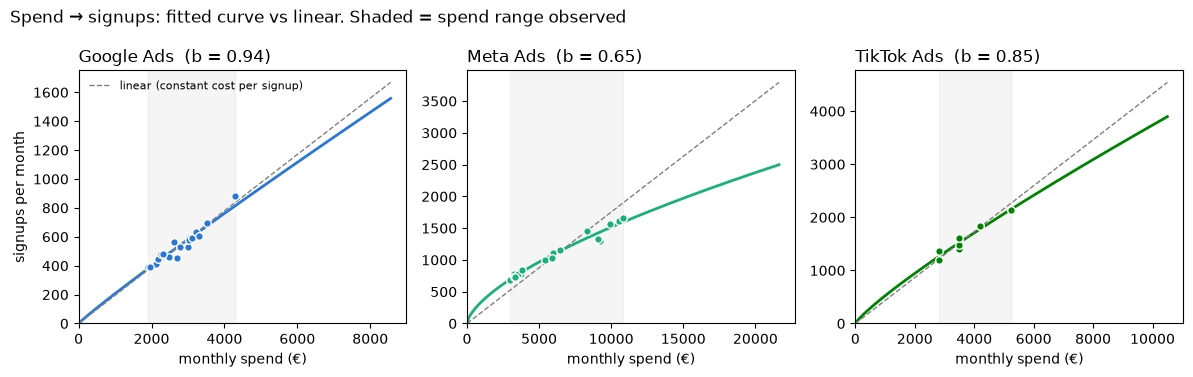

In [7]:
COLOR = {"Google Ads": "#2a78d6", "Meta Ads": "#1baf7a", "TikTok Ads": "#008300"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, ch in zip(axes, COLOR):
    c = curves[ch]
    d = pd.DataFrame({"spend": spend[ch], "signups": signups[ch]}).dropna()
    d = d[d["spend"] > 0]
    x = np.linspace(0, 2 * c["spend_max"], 200)
    ax.plot(x, c["a"] * x ** c["b"], color=COLOR[ch], lw=2)
    ax.plot(x, d["signups"].sum() / d["spend"].sum() * x, color="grey", lw=1, ls="--")
    ax.scatter(d["spend"], d["signups"], color=COLOR[ch], s=30, edgecolor="white", zorder=3)
    ax.axvspan(c["spend_min"], c["spend_max"], color="grey", alpha=0.08)
    ax.set_title(f"{ch}  (b = {c['b']:.2f})", loc="left")
    ax.set_xlabel("monthly spend (€)")
    ax.set_xlim(0)
    ax.set_ylim(0)
axes[0].set_ylabel("signups per month")
axes[0].plot([], [], color="grey", ls="--", lw=1, label="linear (constant cost per signup)")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Spend → signups: fitted curve vs linear. Shaded = spend range observed", x=0.01, ha="left")
plt.tight_layout()
plt.show()